# Đáp án mã · Bài 9 — Hugging Face và tokenizer

Giải **các bài tập của Bài 9** bằng mã chạy được. Cần Internet lần đầu để tải PhoBERT; chạy được trên CPU (GPU nhanh hơn).

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")

ROOT = pathlib.Path.cwd()
while not (ROOT / "nlpvi").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
transformers.logging.set_verbosity_error()
from transformers import AutoModel, AutoTokenizer

from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler

from nlpvi import load_hard, load_splits, normalize, segment, set_seed, tokenize_surface

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
train, valid, test = load_splits(); hard = load_hard()
tok = AutoTokenizer.from_pretrained("vinai/phobert-base")
model = AutoModel.from_pretrained("vinai/phobert-base").eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)
print("PhoBERT trên", device)

PhoBERT trên cuda


## Bài tập 1 — Số phép gộp BPE: 20, 120, 400

Dùng lại `bpe_train` / `bpe_encode` của Bài 9; đo **số mảnh trung bình mỗi âm tiết** trên tập valid theo số phép gộp.

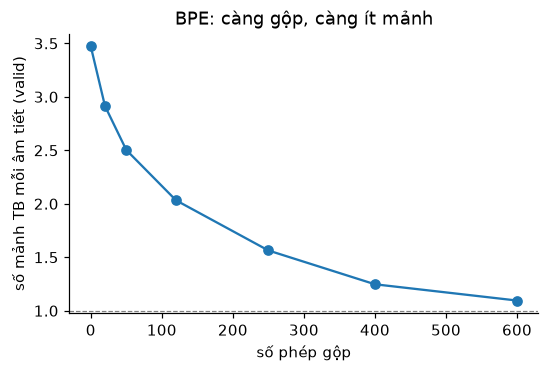

,0,20,50,120,250,400,600
mảnh/âm tiết,3.471,2.914,2.503,2.032,1.564,1.247,1.095


In [2]:
def bpe_train(word_freq, n_merges):
    vocab = {tuple(w) + ("</w>",): f for w, f in word_freq.items()}
    merges = []
    for _ in range(n_merges):
        pairs = Counter()
        for sym, f in vocab.items():
            for a, b in zip(sym, sym[1:]):
                pairs[(a, b)] += f
        if not pairs: break
        best = max(pairs, key=pairs.get); merges.append(best)
        moi = {}
        for sym, f in vocab.items():
            out, i = [], 0
            while i < len(sym):
                if i < len(sym) - 1 and (sym[i], sym[i + 1]) == best: out.append(sym[i] + sym[i + 1]); i += 2
                else: out.append(sym[i]); i += 1
            moi[tuple(out)] = moi.get(tuple(out), 0) + f
        vocab = moi
    return merges

def bpe_encode(word, merges):
    sym = list(word) + ["</w>"]
    for a, b in merges:
        i = 0
        while i < len(sym) - 1:
            if sym[i] == a and sym[i + 1] == b: sym[i:i + 2] = [a + b]
            else: i += 1
    return sym

def am_tiet(df):
    return [w for t in df["text"] for w in tokenize_surface(normalize(t)) if w.isalpha()]

dem_tr = Counter(am_tiet(train))
merges_all = bpe_train(dict(dem_tr), 600)
valid_syll = am_tiet(valid)

def manh_tb(n):
    ms = merges_all[:n]
    cache = {}
    tot = 0
    for w in valid_syll:
        if w not in cache:
            cache[w] = len([x for x in bpe_encode(w, ms) if x != "</w>"])      # không tính ký hiệu hết từ đứng riêng
        tot += cache[w]
    return tot / len(valid_syll)

ns = [0, 20, 50, 120, 250, 400, 600]
kq = {n: manh_tb(n) for n in ns}
plt.figure(figsize=(5.5, 3.3)); plt.plot(list(kq), list(kq.values()), marker="o")
plt.xlabel("số phép gộp"); plt.ylabel("số mảnh TB mỗi âm tiết (valid)"); plt.axhline(1, ls="--", color="gray", lw=.8)
plt.title("BPE: càng gộp, càng ít mảnh"); plt.show()
pd.DataFrame({"mảnh/âm tiết": {n: round(v, 3) for n, v in kq.items()}}).T

**Đọc kết quả (số của bạn có thể lệch nhẹ).** Với 0 phép gộp mỗi âm tiết là chuỗi ký tự (≈3,5 mảnh). Số mảnh giảm **nhanh nhất ở khoảng 100 phép gộp đầu** (≈3,5 → 2,0 ở 120 phép), rồi chậm dần: ≈1,6 ở 250, ≈1,25 ở 400 và ≈1,1 ở 600 — tiệm cận 1 mảnh/âm tiết khi mọi âm tiết phổ biến đã thành *một* mảnh. Chú ý ta đo trên **valid**: âm tiết chưa thấy ở train vẫn bị cắt vụn nên đường cong không bao giờ chạm đúng 1. Đây là đánh đổi cốt lõi: từ điển lớn hơn (nhiều phép gộp hơn) → chuỗi token ngắn hơn nhưng phải học nhiều embedding hơn.

## Bài tập 2 — Có và không tách từ với PhoBERT

In [3]:
@torch.no_grad()
def vec_cau(cac_cau):
    enc = tok(cac_cau, padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
    h = model(**enc).last_hidden_state
    m = enc["attention_mask"].unsqueeze(-1).float()
    v = (h * m).sum(1) / m.sum(1)
    return torch.nn.functional.normalize(v, dim=-1).cpu().numpy()

mau = valid["text"].tolist()[:40]
co_tach = [segment(t) for t in mau]
khong_tach = [" ".join(tokenize_surface(normalize(t))) for t in mau]

n_co = np.mean([len(tok.tokenize(s)) for s in co_tach]); n_khong = np.mean([len(tok.tokenize(s)) for s in khong_tach])
cos = np.sum(vec_cau(co_tach) * vec_cau(khong_tach), axis=1)
print(f"Số token TB / câu: có tách từ = {n_co:.1f} | không tách từ = {n_khong:.1f}  (chênh {n_khong / n_co - 1:+.0%})")
print(f"Cosine giữa vector câu có/không tách từ: TB = {cos.mean():.3f}, nhỏ nhất = {cos.min():.3f}")

Số token TB / câu: có tách từ = 13.1 | không tách từ = 15.4  (chênh +18%)
Cosine giữa vector câu có/không tách từ: TB = 0.823, nhỏ nhất = 0.556


**Đọc kết quả.** Không tách từ → **nhiều token hơn** (≈15,4 so với ≈13,1 mỗi câu, +18%). Vector câu của hai cách **khá giống nhau** (cosine trung bình ≈0,82) vì Transformer có ngữ cảnh để "tự ghép" nghĩa, nhưng **không bằng 1** và có câu chỉ đạt ≈0,56: đầu vào lệch phân phối so với lúc tiền huấn luyện. Cosine cao không có nghĩa là *chất lượng như nhau*: sự khác biệt nhỏ trong vector có thể đủ làm đổi kết quả trên bài toán cụ thể. Cách duy nhất để biết là **đo trên tác vụ đích** (so sánh macro-F1 khi tinh chỉnh có/không tách từ).

## Bài tập 3 — Cosine của "đá" ở các lớp 4, 8, 12

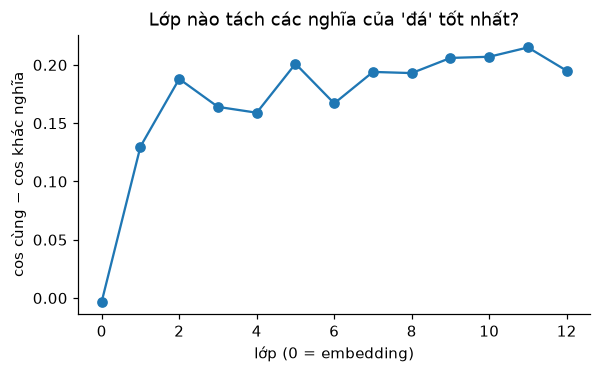

,cos cùng nghĩa,cos khác nghĩa,chênh
lớp,,,
0,0.967,0.970,-0.003
4,0.737,0.577,0.159
8,0.702,0.510,0.193
12,0.751,0.556,0.195


In [4]:
ngu_canh = [("đá bóng", "Anh_ấy đá quả_bóng vào lưới ."), ("đá bóng", "Cầu_thủ đá phạt rất đẹp ."),
            ("hòn đá", "Hòn đá này rất nặng ."), ("hòn đá", "Anh nhặt viên đá ven đường ."),
            ("nước đá", "Cho thêm đá vào ly nước ."), ("nước đá", "Ly trà đá mát lạnh .")]

@torch.no_grad()
def vec_theo_lop(cau, tu="đá"):
    enc = tok(cau, return_tensors="pt").to(device)
    idx = tok.convert_ids_to_tokens(enc["input_ids"][0]).index(tu)
    hs = model(**enc, output_hidden_states=True).hidden_states
    return np.array([(h[0, idx] / h[0, idx].norm()).cpu().numpy() for h in hs])      # (13 lớp, 768)

V = np.stack([vec_theo_lop(c) for _, c in ngu_canh])                                # (6, 13, 768)
rows = []
for lop in range(13):
    M = V[:, lop] @ V[:, lop].T
    cung = np.mean([M[i, j] for i, j in [(0, 1), (2, 3), (4, 5)]])
    khac = np.mean([M[i, j] for i in range(6) for j in range(6) if i // 2 != j // 2])
    rows.append({"lớp": lop, "cos cùng nghĩa": cung, "cos khác nghĩa": khac, "chênh": cung - khac})
tbl = pd.DataFrame(rows).set_index("lớp").round(3)
plt.figure(figsize=(6, 3.3)); plt.plot(tbl.index, tbl["chênh"], marker="o"); plt.xlabel("lớp (0 = embedding)"); plt.ylabel("cos cùng − cos khác nghĩa")
plt.title("Lớp nào tách các nghĩa của 'đá' tốt nhất?"); plt.show()
tbl.loc[[0, 4, 8, 12]]

**Đọc kết quả.** Ở lớp 0 (embedding tĩnh) độ tách **bằng 0** (cos cùng nghĩa ≈ cos khác nghĩa ≈ 0,97). Nó **tăng vọt** từ lớp 0 đến lớp 4 (≈0,16) rồi gần như **bão hòa** ở lớp 8–12 (≈0,19–0,20): các lớp giữa và cao mang nghĩa theo ngữ cảnh gần như ngang nhau với từ "đá". Với tác vụ khác, lớp tốt nhất có thể là một lớp giữa chứ không phải lớp cuối (lớp cuối được "chuyên hóa" cho nhiệm vụ dự đoán từ bị che). Bài học thực hành: khi dùng PhoBERT **đóng băng** làm đặc trưng, đừng mặc định lấy lớp cuối — hãy thử các lớp giữa hoặc trung bình nhiều lớp. Lưu ý mẫu rất nhỏ (6 câu).

## Bài tập 4 — Đặc trưng PhoBERT đóng băng + Logistic Regression

Không tinh chỉnh PhoBERT; chỉ lấy vector câu (trung bình, lớp cuối) làm đặc trưng. So với TF-IDF (Bài 3).

In [5]:
@torch.no_grad()
def dac_trung(texts, bs=32):
    out = []
    for i in range(0, len(texts), bs):
        enc = tok([segment(t) for t in texts[i:i + bs]], padding=True, truncation=True, max_length=96, return_tensors="pt").to(device)
        h = model(**enc).last_hidden_state; m = enc["attention_mask"].unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).cpu())
    return torch.cat(out).numpy()

import time
t0 = time.time()
Xtr, Xva, Xh = dac_trung(train["text"].tolist()), dac_trung(valid["text"].tolist()), dac_trung(hard["text"].tolist())
print(f"trích đặc trưng {len(train) + len(valid) + len(hard)} câu trong {time.time() - t0:.0f}s trên {device}")

sc = StandardScaler().fit(Xtr)
lr_pho = LogisticRegression(max_iter=3000, C=1.0).fit(sc.transform(Xtr), train["label"])
tf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")
lr_tf = LogisticRegression(C=10, max_iter=3000).fit(tf.fit_transform(train["text"].map(normalize)), train["label"])
f = lambda y, p: round(f1_score(y, p, average="macro"), 3)
pd.DataFrame({"valid macro-F1": {"PhoBERT đóng băng + LR": f(valid["label"], lr_pho.predict(sc.transform(Xva))),
                                 "TF-IDF + LR": f(valid["label"], lr_tf.predict(tf.transform(valid["text"].map(normalize))))},
              "câu khó macro-F1": {"PhoBERT đóng băng + LR": f(hard["label"], lr_pho.predict(sc.transform(Xh))),
                                   "TF-IDF + LR": f(hard["label"], lr_tf.predict(tf.transform(hard["text"].map(normalize))))}})

trích đặc trưng 1571 câu trong 9s trên cuda


,valid macro-F1,câu khó macro-F1
PhoBERT đóng băng + LR,0.873,0.647
TF-IDF + LR,0.886,0.563


**Đọc kết quả.** Trên **bộ tổng hợp** này TF-IDF vốn đã rất mạnh (khuôn câu lặp lại, từ khóa quyết định) nên đặc trưng PhoBERT đóng băng **không vượt** nó trên `valid` (≈0,87 so với ≈0,89). Điểm đáng chú ý nằm ở **câu khó** (khác khuôn câu): PhoBERT đóng băng đạt ≈0,65 so với ≈0,56 của TF-IDF — đặc trưng ngữ cảnh giữ tốt hơn khi gặp cấu trúc mới (chỉ 40 câu nên mang tính gợi ý). Với dữ liệu *thật*, đặc trưng đóng băng + tuyến tính thường là một baseline mạnh, rẻ (không cần GPU để huấn luyện) trước khi tinh chỉnh toàn bộ ở Bài 10. Hãy so cả ba mức: TF-IDF, PhoBERT đóng băng, PhoBERT tinh chỉnh.

## Bài tập 5 (khó) — WordPiece so với BPE

WordPiece chọn cặp gộp theo $\dfrac{\text{count}(ab)}{\text{count}(a)\,\text{count}(b)}$ (một dạng PMI) thay vì tần suất thô $\text{count}(ab)$. Ta cài và so sánh các phép gộp đầu.

In [6]:
def wordpiece_train(word_freq, n_merges, min_count=2):
    vocab = {tuple(w) + ("</w>",): f for w, f in word_freq.items()}
    merges = []
    for _ in range(n_merges):
        pair_c, sym_c = Counter(), Counter()
        for sym, f in vocab.items():
            for a in sym: sym_c[a] += f
            for a, b in zip(sym, sym[1:]): pair_c[(a, b)] += f
        if not pair_c: break
        diem = {p: c / (sym_c[p[0]] * sym_c[p[1]]) for p, c in pair_c.items() if c >= min_count}      # bỏ cặp quá hiếm
        if not diem: break
        best = max(diem, key=diem.get); merges.append(best)
        moi = {}
        for sym, f in vocab.items():
            out, i = [], 0
            while i < len(sym):
                if i < len(sym) - 1 and (sym[i], sym[i + 1]) == best: out.append(sym[i] + sym[i + 1]); i += 2
                else: out.append(sym[i]); i += 1
            moi[tuple(out)] = moi.get(tuple(out), 0) + f
        vocab = moi
    return merges

wp2 = wordpiece_train(dict(dem_tr), 15, min_count=2)
wp30 = wordpiece_train(dict(dem_tr), 15, min_count=30)
pd.DataFrame({"BPE (tần suất thô)": [a + "+" + b for a, b in merges_all[:15]],
              "WordPiece, ngưỡng cặp ≥ 2": [a + "+" + b for a, b in wp2],
              "WordPiece, ngưỡng cặp ≥ 30": [a + "+" + b for a, b in wp30]})

,BPE (tần suất thô),"WordPiece, ngưỡng cặp ≥ 2","WordPiece, ngưỡng cặp ≥ 30"
0,n+g,x+ỉ,s+ẽ
1,ng+</w>,x+é,d+ù
2,n+</w>,x+ử,b+ù
3,i+</w>,x+ứ,l+ý
4,n+h,s+ẽ,k+ỳ
5,c+</w>,d+ẫ,v+ừ
6,t+h,b+è,y+ê
7,t+</w>,d+ù,s+ắ
8,c+h,b+ù,ư+ợ
9,k+h,d+ễ,r+ấ


**Đọc kết quả — kết quả ngược với trực giác.** BPE gộp trước các cặp **phổ biến nhất** (`n+g`, `n+h`, `t+h`...: âm ghép của tiếng Việt). Với WordPiece chấm điểm thô $\frac{\text{count}(ab)}{\text{count}(a)\,\text{count}(b)}$, các phép gộp đầu lại là **cặp ký tự hiếm vô tình đi liền nhau** (ví dụ `x+ỉ`, `x+é`, `s+ẽ`): vì mẫu số là tích tần suất của hai thành phần, cặp *hiếm* có điểm rất lớn dù chỉ xuất hiện vài lần. Đó là hiện tượng **thiên lệch về cặp hiếm** của PMI. Khi nâng **ngưỡng tần suất cặp** lên ≥30, danh sách *vẫn* toàn cặp "hiếm nhưng dính" (`s+ẽ`, `d+ù`, `b+ù`...) — nhiều cặp trong đó thật ra là một âm tiết trọn vẹn rất ngắn ("sẽ", "lạ", "vừa" xuất hiện ở các dòng sau), nên vô hại; điểm khác biệt chính là **thứ tự ưu tiên** (độ "dính" so với độ phổ biến), không phải chất lượng từ điển cuối cùng. Trong cài đặt thật (như WordPiece của BERT), điểm số đi kèm các ngưỡng tần suất tối thiểu và thủ thuật chuẩn hóa; nó *không* chỉ là tỉ lệ thô. Bài học: một công thức đẹp trên giấy cần **được thử trên dữ liệu** — và **nên nhìn kết quả** thay vì tin mô tả. Sau nhiều phép gộp, hai thuật toán cho từ điển khá giống nhau; khác biệt chủ yếu ở các phép gộp đầu và ở cách mã hóa từ mới (WordPiece mã hóa theo *khớp dài nhất*, BPE áp các phép gộp theo thứ tự đã học).